In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np

from polyergalio.models.model_loss import MSELoss
from polyergalio.models.optimizers import SGD, Adam
from polyergalio.models.layers import (
    FullyConnectedLayer,
    DropoutLayer,
    NormalizeLayer,
    RMSNormLayer,
    FrequencyFFT,
    SpectreAttention,
    LatentExpand,
    SpectreDecoderAttention,
    MixtureOfExperts,
    LatentStack, LatentSum, ShiftRight, PoolingLayer
)

from polyergalio.models.embedding.positional import SinusoidEmbedding

import matplotlib.pyplot as plt

MAX_POSSIBLE_WINDOWS = 2**10


In [2]:
from polyergalio.encoders.audio_encoders import (AudioProcessor,
                                              read_wav,
                                              window_size_from_ms,
                                              plot_waveform,
                                              plot_spectrogram,
                                              plot_window_spectra,
                                              build_windows,
                                              progressive_downsample)

WINDOW_LENGTH_MS = 600 # our window length for plotting
sample_rate, waveform_l = read_wav("../test.wav", channel=0)
sample_rate, waveform_r = read_wav("../test.wav", channel=1)

time_per_sample = 1000 / sample_rate
samples_per_window = window_size_from_ms(sample_rate, WINDOW_LENGTH_MS)
# samples_per_window = WINDOW_LENGTH_MS / time_per_sample
real_positive_fft_shape = (samples_per_window // 2) + 1


print(time_per_sample, "ms per sample step")
print(f"Each {WINDOW_LENGTH_MS} ms window will be composed of {samples_per_window} samples")
print(f"Fourier Transform will yield {real_positive_fft_shape} frequency bins")

audio_enc = AudioProcessor(
    sample_rate=sample_rate,
    window_ms = WINDOW_LENGTH_MS,
    overlap_ratio= 1/3, # how much of the window is overlapping with previous step
    use_decibels = True,
    target = "waveform",
)


encoded_data = audio_enc.fit_encode(waveform_l)
print(audio_enc.metadata)
print("amplitude", encoded_data["amplitude"].shape, "\nfrequency spectrum:", encoded_data["spectrum"].shape)


0.010416666666666666 ms per sample step
Each 600 ms window will be composed of 57600 samples
Fourier Transform will yield 28801 frequency bins
{'target': 'waveform', 'channel': 0, 'sample_rate': 96000, 'window_ms': 600, 'window_size': 57600, 'num_overlap': 19200, 'num_frequencies': 28801, 'use_decibels': True}
amplitude (19, 57600) 
frequency spectrum: (19, 28801)


/Users/david/Library/CloudStorage/Dropbox/CODE/tools/ml-tools/src/polyergalio/encoders/audio_encoders.py:108: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, waveform = wavfile.read(file_path)


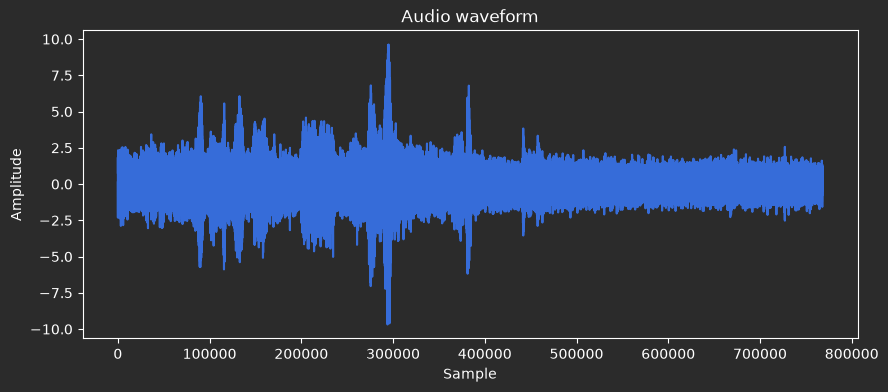

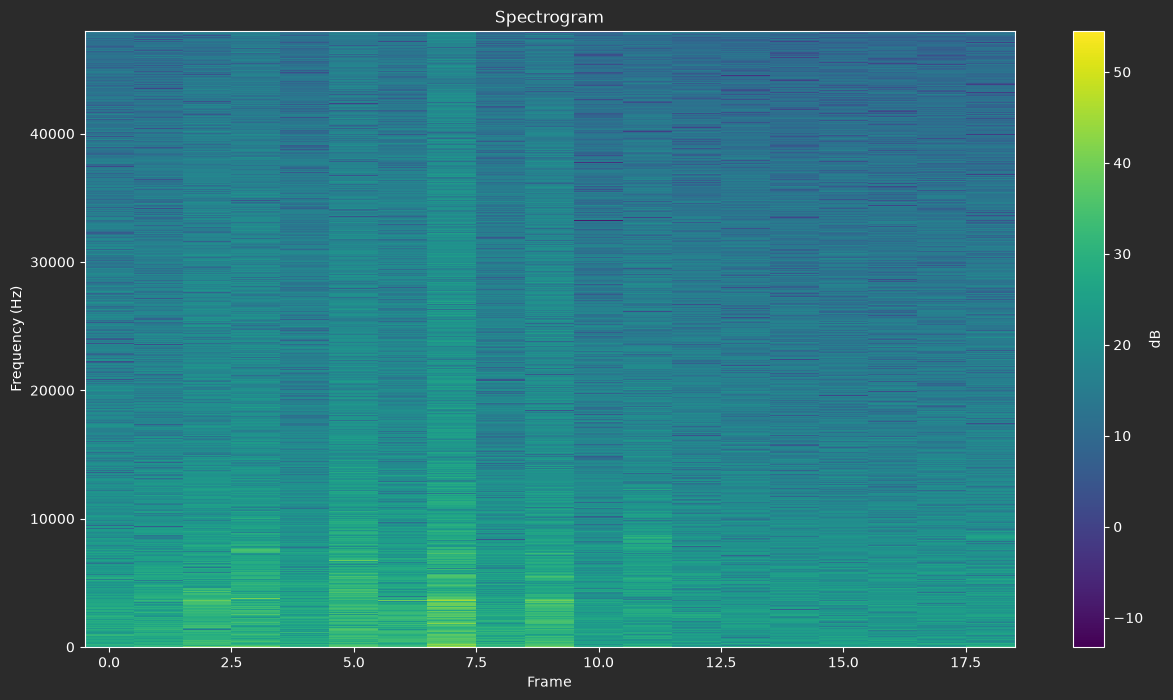

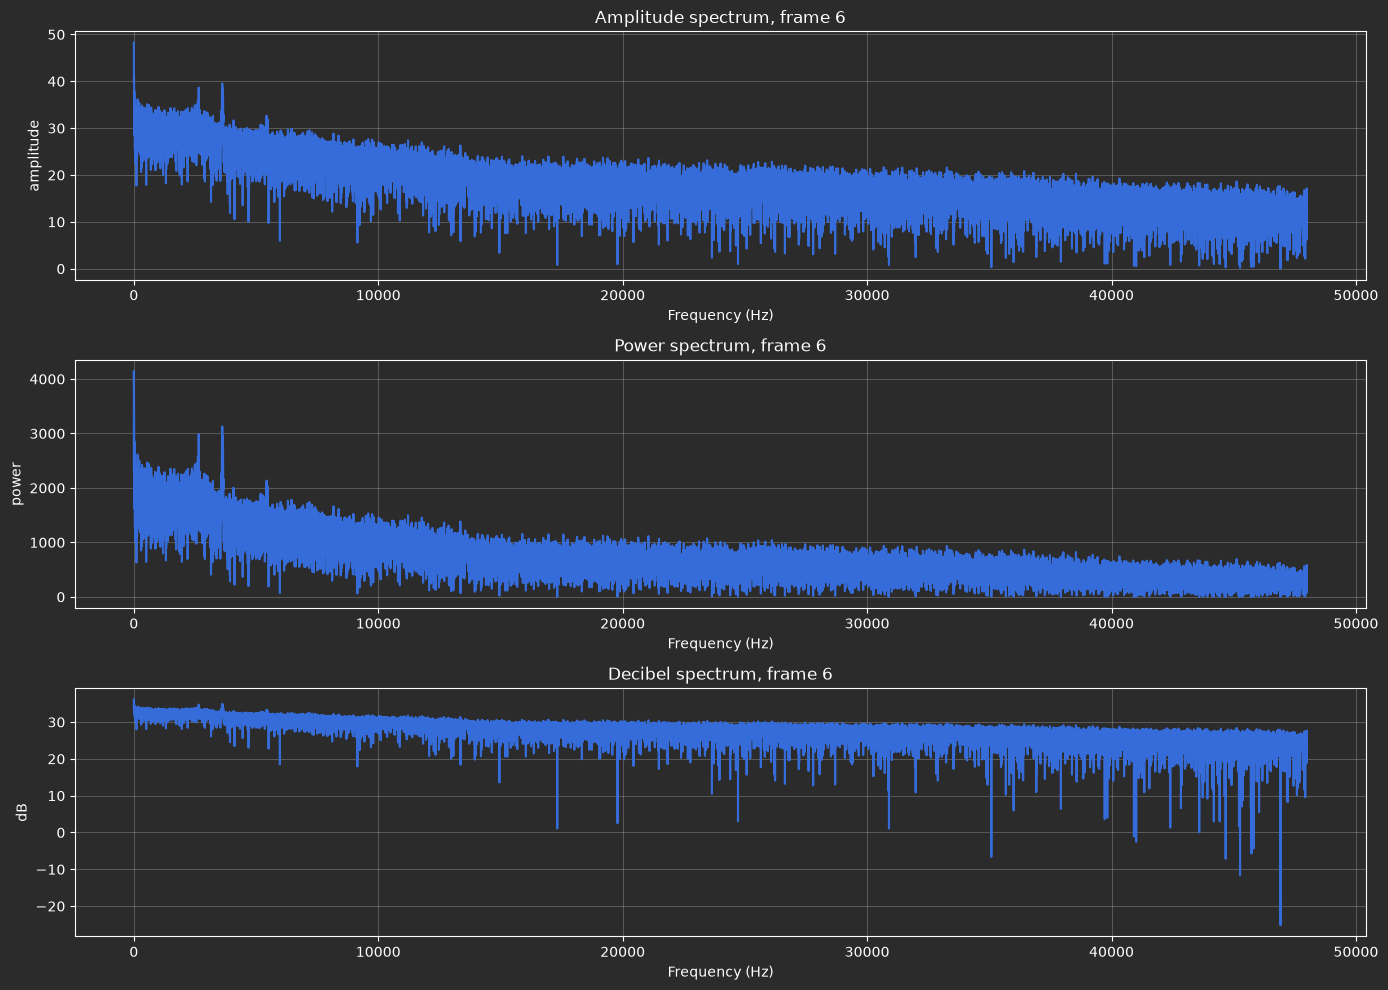

In [3]:
plot_waveform(waveform_l)
plot_spectrogram(encoded_data["spectrum"].real, audio_enc.freqs)
plot_window_spectra(
        encoded_data["spectrum"].real, audio_enc.freqs, index=6, window_size=time_per_sample
    )


In [4]:
# loading our audio files:
import os
WINDOW_LENGTH_MS = 50 # our window length

all_windowed_data = []

all_filenames = os.listdir(f"../data/")
for fn in all_filenames:
    if fn.endswith(".wav"):

        sample_rate, waveform_l = read_wav(f"../data/{fn}", channel=0)
        time_per_sample = 1000 / sample_rate
        samples_per_window = window_size_from_ms(sample_rate, WINDOW_LENGTH_MS)
        # samples_per_window = WINDOW_LENGTH_MS / time_per_sample
        real_positive_fft_shape = (samples_per_window // 2) + 1


        audio_enc = AudioProcessor(
            sample_rate=sample_rate,
            window_ms = WINDOW_LENGTH_MS,
            overlap_ratio= 1/4, # how much of the window is overlapping with previous step
            use_decibels = True,
            target = "waveform",
        )

        encoded_data_l = audio_enc.fit_encode(waveform_l)["amplitude"]
        list_of_array = [encoded_data_l]

        try:
            sample_rate, waveform_r = read_wav(f"../data/{fn}", channel=1)
            encoded_data_r = audio_enc.fit_encode(waveform_r)["amplitude"]
            list_of_array.append(encoded_data_r)
        except:
            pass

        all_windowed_data.extend(list_of_array)

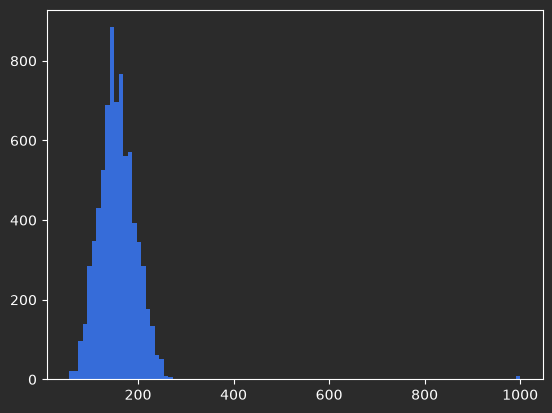

3941


In [5]:
shapes = []
np.random.shuffle(all_windowed_data)

for windowed_data in all_windowed_data:
    shapes.append(windowed_data.shape[0])

plt.hist(np.clip(shapes, min=0, max=1000), bins=100)
plt.show()
print(np.max(shapes))

In [6]:
# MAX_POSSIBLE_WINDOWS should be optimized for specific lengths of FFT: closest to: (2**10 * N)
# MAX_POSSIBLE_WINDOWS = 2**10 * 1
MAX_POSSIBLE_WINDOWS = 600


# pad our sequences to max:
xs = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS, samples_per_window))
padding_mask = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS))
for idx, data in enumerate(all_windowed_data):
    l, n = data.shape
    l = min(l, MAX_POSSIBLE_WINDOWS)
    xs[idx, :l, :] = data[:l, ...]
    padding_mask[idx, :l] = 1

print(xs.shape)
print(padding_mask.shape)

(7504, 600, 200)
(7504, 600)


In [7]:
# downsample the data -- this could be helpful? or not... not sure yet.
#
# downs = progressive_downsample(xs, mask=padding_mask, factors=[2, 2, 2])
#
# for dim in downs:
#     print(dim[0].shape, dim[1].shape)

# let's take a subsample of the data
# xs = xs[:500, ...]
# padding_mask = padding_mask[:500, ...]

In [8]:
print(xs.shape, padding_mask.shape)

(7504, 600, 200) (7504, 600)


In [9]:
MAX_POSSIBLE_WINDOWS

600

In [10]:
from polyergalio.models.network import Network
from polyergalio.visuals.nnet_visuals import plot_network


EMBEDDING_DIM = 1200
HIDDEN_DIM = 800
# MAX_POSSIBLE_WINDOWS
NUM_HEADS=10
# latent space bottleneck
LATENT_DIMENSION = 1200

# samples_per_window = the samples per window (final dimesion of xs)

net = Network(name="audio_encoder_decoder", input_shape=(samples_per_window,))
windows = net.input

# (num_samples, seq_length, window_dimension)
# amplitude branch: funnel the raw window down to the latent width
amplitude = net.connect(FullyConnectedLayer(samples_per_window, EMBEDDING_DIM, "relu"), windows, name="amp_a")
amplitude = net.connect(FullyConnectedLayer(EMBEDDING_DIM, real_positive_fft_shape, "relu"), amplitude, name="amp_b")
amplitude = net.connect(FullyConnectedLayer(real_positive_fft_shape, EMBEDDING_DIM, "linear"), amplitude, name="amp_c")

# frequency branch. `windows` is used a second time here, which is the fan-out
frequency = net.connect(FrequencyFFT(MAX_POSSIBLE_WINDOWS, samples_per_window), windows, name="freq_fft")
frequency = net.connect(FullyConnectedLayer(samples_per_window, EMBEDDING_DIM, "linear"), frequency, name="freq_fc")

# the branches merge, then get positional information
mixed = net.connect(LatentStack(), amplitude, frequency, name="stack")
mixed = net.connect(SinusoidEmbedding(MAX_POSSIBLE_WINDOWS, 2 * EMBEDDING_DIM), mixed, name="position")
mixed = net.connect(
    FullyConnectedLayer(input_dimension=2*EMBEDDING_DIM,
                        output_dimension=HIDDEN_DIM,
                        activation_type="linear"),
    mixed, name="project")

# encoder
enc = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                    hidden_dimension=HIDDEN_DIM,
                                    num_heads=NUM_HEADS,
                                    band_radius=20,
                                    memory_tokens=150,
                                    use_wrm=True),
                   mixed, name="enc0_attn")
enc = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), enc, name="enc0_a")
enc = net.connect(RMSNormLayer(input_dimension=HIDDEN_DIM), enc, name="enc0_norm")
enc = net.connect(DropoutLayer(dropout_prob=0.05), enc, name="enc0_drop")


for _ in range(1, 12):
    enc = net.connect(LatentSum(), mixed, enc, name=f"enc{_}_residualconn")
    enc = net.connect(RMSNormLayer(input_dimension=HIDDEN_DIM), enc, name=f"enc{_}_prenorm")
    enc = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                        hidden_dimension=HIDDEN_DIM,
                                        num_heads=NUM_HEADS,
                                        band_radius=10,
                                        memory_tokens=150,
                                        use_wrm=True), enc, name=f"enc{_}_attn")
    enc = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"),
                       enc, name=f"enc{_}_a")
    enc = net.connect(RMSNormLayer(input_dimension=HIDDEN_DIM), enc, name=f"enc{_}_norm")
    enc = net.connect(DropoutLayer(dropout_prob=0.05), enc, name=f"enc{_}_drop")

#  Latent --------------------------------------------------------------------------------
latent = net.connect(LatentSum(), mixed, enc, name="latentresid")
latent = net.connect(RMSNormLayer(HIDDEN_DIM), latent, name="latent_prenorm")
latent = net.connect(PoolingLayer(), latent, name="latent_pooled")

decoder_in = net.connect(LatentExpand(MAX_POSSIBLE_WINDOWS, HIDDEN_DIM), latent, name="dec_in")
i=0
decoder = net.connect(RMSNormLayer(HIDDEN_DIM), decoder_in, name=f"dec{i}_prenorm")
decoder = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                       hidden_dimension=HIDDEN_DIM,
                                       num_heads=NUM_HEADS,
                                       band_radius=10,
                                       memory_tokens=150,
                                       use_wrm=True),
                  decoder, name=f"dec{i}_attn")
decoder = net.connect(LatentSum(), decoder_in, decoder, name=f"dec{i}_residual")
decoder = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), decoder, name=f"dec{i}_fc")

for i in range(1, 4):
    decoder = net.connect(RMSNormLayer(HIDDEN_DIM), decoder, name=f"dec{i}_prenorm")
    decoder = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                           hidden_dimension=HIDDEN_DIM,
                                           num_heads=NUM_HEADS,
                                           band_radius=10,
                                           memory_tokens=150,
                                           use_wrm=True),
                      decoder, name=f"dec{i}_attn")
    decoder = net.connect(LatentSum(), decoder_in, decoder, name=f"dec{i}_residual")
    decoder = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), decoder, name=f"dec{i}_fc")

head = net.connect(MixtureOfExperts(input_dim=HIDDEN_DIM,
                                    upscale_dim=int(1.5*HIDDEN_DIM),
                                    hidden_dim=HIDDEN_DIM,
                                    num_shared_experts=2,
                                    num_routed_experts=32,
                                    top_k=9,
                                    activation_type="swish",
                                    gate_activation="sigmoid",
                                    routed_scaling=1.25,
                                    num_groups=16,
                                    top_groups=8),
                   decoder,
                   name="moe_head")
# head = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), head, name="head_fc_a")
# head = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), head, name="head_fc_b")
head = net.connect(NormalizeLayer(HIDDEN_DIM, shift_scale=True), head, name="head_norm")

net.output = net.connect(FullyConnectedLayer(HIDDEN_DIM, samples_per_window, "linear", is_output=True),
                         head,
                         name="head_output")


print("edges:")
for producer, consumer in net.edges():
    print(f"  {producer:10s} -> {consumer}")


edges:
  input      -> amp_a
  amp_a      -> amp_b
  amp_b      -> amp_c
  input      -> freq_fft
  freq_fft   -> freq_fc
  amp_c      -> stack
  freq_fc    -> stack
  stack      -> position
  position   -> project
  project    -> enc0_attn
  enc0_attn  -> enc0_a
  enc0_a     -> enc0_norm
  enc0_norm  -> enc0_drop
  project    -> enc1_residualconn
  enc0_drop  -> enc1_residualconn
  enc1_residualconn -> enc1_prenorm
  enc1_prenorm -> enc1_attn
  enc1_attn  -> enc1_a
  enc1_a     -> enc1_norm
  enc1_norm  -> enc1_drop
  project    -> enc2_residualconn
  enc1_drop  -> enc2_residualconn
  enc2_residualconn -> enc2_prenorm
  enc2_prenorm -> enc2_attn
  enc2_attn  -> enc2_a
  enc2_a     -> enc2_norm
  enc2_norm  -> enc2_drop
  project    -> enc3_residualconn
  enc2_drop  -> enc3_residualconn
  enc3_residualconn -> enc3_prenorm
  enc3_prenorm -> enc3_attn
  enc3_attn  -> enc3_a
  enc3_a     -> enc3_norm
  enc3_norm  -> enc3_drop
  project    -> enc4_residualconn
  enc3_drop  -> enc4_residual


audio_encoder_decoder: 101 nodes, 146509621 parameters
  node                sources                    shape
  amp_a               input                      (1200,)
  amp_b               amp_a                      (101,)
  amp_c               amp_b                      (1200,)
  freq_fft            input                      (None, 200)
  freq_fc             freq_fft                   (1200,)
  stack               amp_c,freq_fc              (2400,)
  position            stack                      (2400,)
  project             position                   (800,)
  enc0_attn           project                    (800,)
  enc0_a              enc0_attn                  (800,)
  enc0_norm           enc0_a                     (800,)
  enc0_drop           enc0_norm                  (800,)
  enc1_residualconn   project,enc0_drop          (None,)
  enc1_prenorm        enc1_residualconn          (800,)
  enc1_attn           enc1_prenorm               (800,)
  enc1_a              enc1_attn       

<Axes: title={'center': 'audio_encoder_decoder'}>

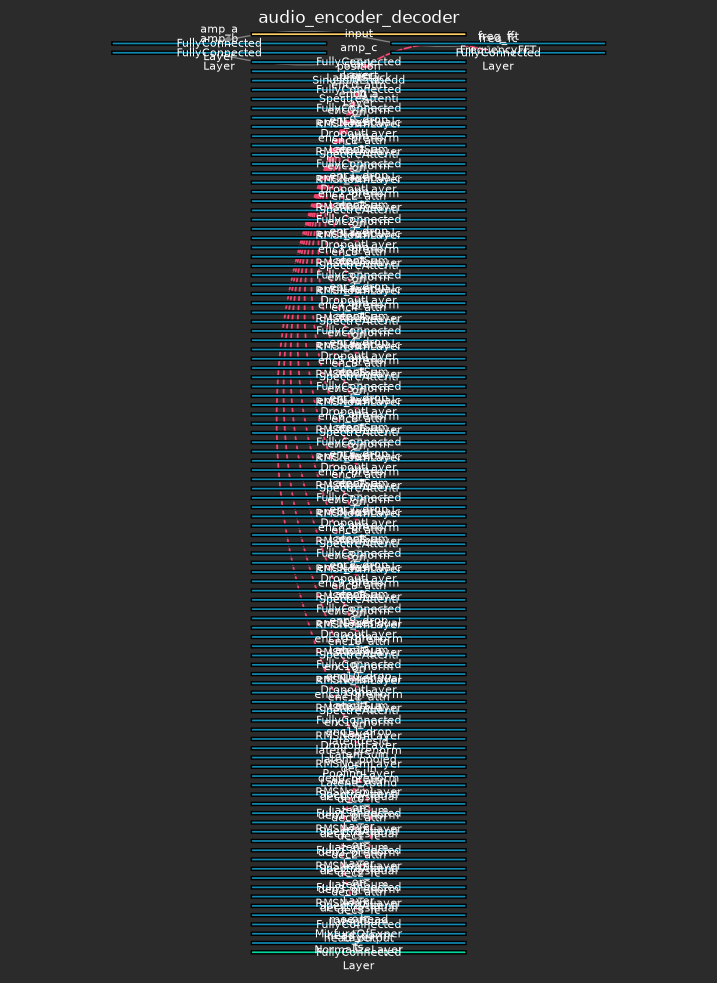

In [11]:
print()
print(net.summary())
plot_network(net)

In [12]:
net.eval()
net.forward(xs[:5, ...])
print(net.timing_summary(top=10))

audio_encoder_decoder: per-node timing
  node         fwd avg (ms)  fwd total (s)  bwd avg (ms)  bwd total (s)
  moe_head         1459.507         1.4595         0.000         0.0000
  dec2_attn         131.120         0.1311         0.000         0.0000
  dec3_attn         130.072         0.1301         0.000         0.0000
  enc8_attn         129.507         0.1295         0.000         0.0000
  enc11_attn        128.208         0.1282         0.000         0.0000
  enc2_attn         122.760         0.1228         0.000         0.0000
  dec0_attn         118.089         0.1181         0.000         0.0000
  enc5_attn         116.620         0.1166         0.000         0.0000
  enc10_attn        116.530         0.1165         0.000         0.0000
  enc6_attn         115.917         0.1159         0.000         0.0000


In [14]:
net.serialize("elephant_reconstruction.ergalio")

{'type': 'Network',
 'version': '0.1.7',
 'config': {'name': 'audio_encoder_decoder',
  'input_shape': (200,),
  'data_type': numpy.float64,
  'complex_data_type': numpy.complex128},
 'state': {'nodes': {'amp_a': {'sources': ['input'],
    'component': {'type': 'FullyConnectedLayer',
     'version': '0.1.7',
     'config': {'input_dimension': 200,
      'output_dimension': 1200,
      'activation_type': 'relu',
      'is_output': False,
      'initialization_override': None,
      'initialization_kwargs': {}},
     'state': {'weights': array([[-0.06513081,  0.09718666, -0.02250928, ...,  0.12988646,
               0.15354916,  0.03677512],
             [-0.02185289, -0.17658524,  0.08320934, ...,  0.06128383,
              -0.09823746, -0.01309356],
             [-0.02469249,  0.07572205,  0.06550977, ..., -0.06959414,
              -0.11359086,  0.03626317],
             ...,
             [-0.0005817 , -0.04934177, -0.08871749, ..., -0.13947071,
               0.0097752 ,  0.01305594]

In [ ]:
# AND this is how we train:
%pdb on
BATCH_SIZE = 8
EPOCHS = 10
STEPS_PER_SAMPLE = 5
LR = 4e-4
DIVI = 10

loss = MSELoss()
optimizer = Adam(LR)
all_losses = []
verbose = True
idx_shuffler = np.arange(len(xs))


for epoch in range(EPOCHS):
    net.train()
    print(f'EPOCH {epoch}, lr decaying to {LR}')

    np.random.shuffle(idx_shuffler)

    # decay rate for LR
    optimizer.learning_rate *= 0.96

    _permuted_xs = xs[idx_shuffler, ...]
    _permuted_mask = padding_mask[idx_shuffler, ...]
    for step_i, batch_st in enumerate(range(0, len(xs), BATCH_SIZE)):
        verbose = (step_i + 1) % DIVI == 0

        _xs = _permuted_xs[batch_st:batch_st+BATCH_SIZE, :, :]
        _pad = _permuted_mask[batch_st:batch_st+BATCH_SIZE, :]

        # break if we don't have enough samples left
        if _xs.shape[0] != BATCH_SIZE:
            continue
        for _ in range(STEPS_PER_SAMPLE):

            x_prime = net.forward(_xs, mask=_pad)
            reconstruction_loss = loss.forward(prediction=x_prime, targets=_xs, mask=_pad)

            all_losses.append(reconstruction_loss.item())

            net.backward(loss.backward())
            optimizer.step(net)
            net.zero_gradients()

        if verbose:
            print(f"step {_ + 1:4d}  reconstruction loss {reconstruction_loss:.6f}")
            plt.plot(all_losses[-STEPS_PER_SAMPLE:])
            plt.show()

    print(f"step {step_i + 1:4d}  reconstruction loss {reconstruction_loss:.6f}")
    plt.plot(all_losses)
    plt.title("reconstruction loss")
    plt.show()
    net.serialize("elephant_spectre_enc_dec_reconstruction.ergalio")

plt.plot(all_losses)
plt.title("reconstruction loss")
plt.show()

Automatic pdb calling has been turned ON
EPOCH 0, lr decaying to 0.0004


In [15]:
net.serialize("elephant_spectre_enc_dec_reconstruction.ergalio")

AttributeError: LatentExpand: constructor arguments without an attribute: ['base_freq']

> /Users/david/Library/CloudStorage/Dropbox/CODE/tools/ml-tools/src/polyergalio/base_model.py(202)get_config()
    200         missing = [name for name in names if not hasattr(self, name)]
    201         if missing:
--> 202             raise AttributeError(f"{self.__class__.__name__}: constructor arguments without an attribute: {missing}")
    203         return {name: getattr(self, name) for name in names}
    204 



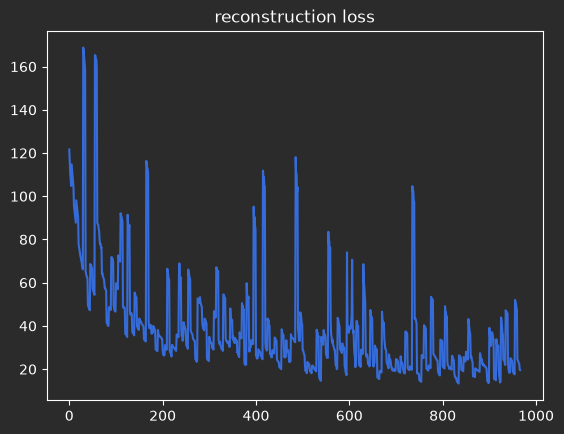

In [68]:
windowed_data.shape
x_prime.shape
plt.plot(all_losses)
plt.title("reconstruction loss")
plt.show()

In [75]:
net.eval()
_xs = _permuted_xs[batch_st:batch_st+BATCH_SIZE, :, :]
_pad = _permuted_mask[batch_st:batch_st+BATCH_SIZE, :]
x_prime = net.forward(_xs, mask=_pad)


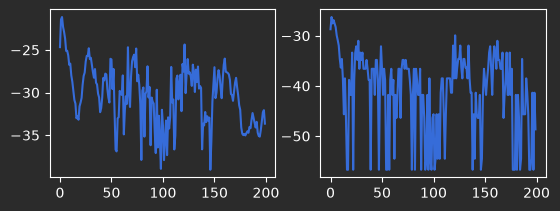

In [80]:
idx=5
plt.figure()
plt.subplot(2,2, 1)
plt.plot(x_prime[0, idx, :])
plt.subplot(2,2, 2)
plt.plot(_xs[0, idx, :])

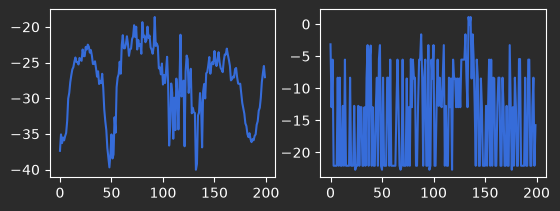

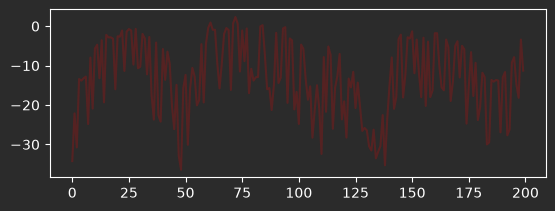

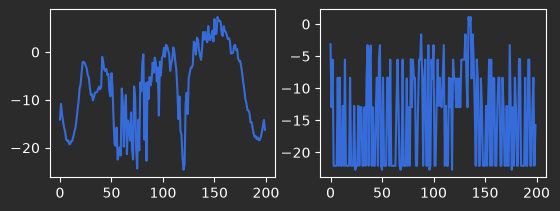

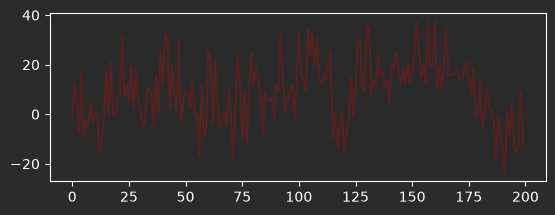

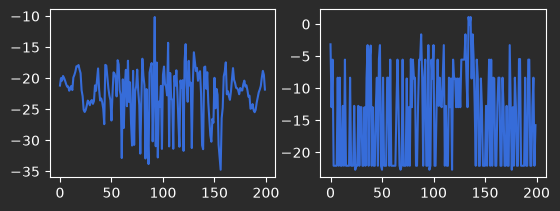

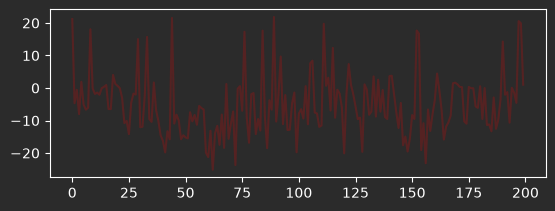

In [66]:
# visualize some of the input data and predictions

for idx in range(min(x_prime.shape[0], 3)):
    plt.figure()
    plt.subplot(2,2, 1)
    plt.plot(x_prime[idx, 3, :])
    plt.subplot(2,2, 2)
    plt.plot(xs[0, 3, :])
    plt.show()
    plt.subplot(2,2, (3,4))
    plt.plot((x_prime[idx, 3, :] - xs[idx, 3, :]), color="red", alpha=0.2)
    plt.show()